In [1]:
import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import GrandTourLoader

# Make sure we can import from data_labeling_pipeline/src when running this notebook from tests/
# repo_root = Path.cwd().resolve().parents[0]
# src_path = repo_root / "src"
# if str(src_path) not in sys.path:
#     sys.path.insert(0, str(src_path))

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

Using mission_path: /datahome/lmertens/grand_tour_dataset/2024-10-01-11-29-55
Median dt: 0.050s, regular diffs: 5160/5190


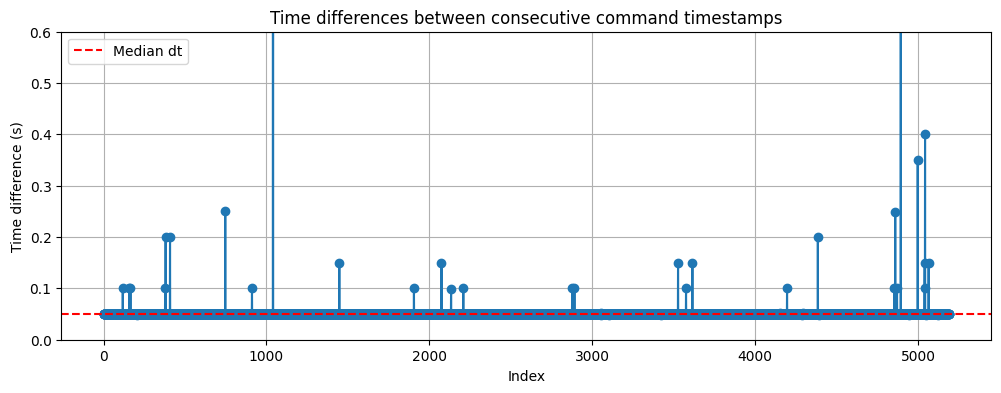

Median dt: 0.050s, regular diffs: 5160/5190
Loaded raw topic dictionaries:
- anymal_command_twist keys: ['angular', 'linear', 'sequence_id', 'timestamp']
- cpt7_ie_tc_odometry keys: ['pose_cov', 'pose_orien', 'pose_pos', 'sequence_id', 'timestamp', 'twist_ang', 'twist_cov', 'twist_lin']

Loaded synchronized outputs:
- shared_ts shape: (2729,)
- U shape: (2729, 2) (v_cmd, omega_cmd)
- Z shape: (2729, 3) (x, y, theta)


In [2]:
# Candidate mission paths (first existing path is used)
from shared_utils.paths import DATASET_ROOT
from data_labeling_pipeline.dataset_loader import fill_command_gaps_with_zero_commands

mission_path = DATASET_ROOT / "2024-10-01-11-29-55"
if not (mission_path.exists() and (mission_path / "data").is_dir()):
    raise FileNotFoundError(
        "Could not find a mission folder with a 'data/' directory. "
        "Set MISSION_PATH in your environment or edit the candidates list in this cell."
    )

print(f"Using mission_path: {mission_path}")
loader = GrandTourLoader(mission_path)

# Topics used by load_data_shared_timestamps()
cmd_data = loader.load_topic("anymal_command_twist")
ts, v_cmd, omega_cmd = fill_command_gaps_with_zero_commands(
    cmd_data["timestamp"], cmd_data["linear"], cmd_data["angular"]
)

# Plot the differences in timestamps to check for regularity and gaps.
diffs = np.diff(cmd_data["timestamp"])
plt.figure()
plt.plot(diffs, marker="o")
plt.axhline(np.median(diffs), color="r", linestyle="--", label="Median dt")
plt.xlabel("Index")
plt.ylabel("Time difference (s)")
plt.title("Time differences between consecutive command timestamps")
plt.ylim(0, 0.6)
plt.legend()
plt.show()

cmd_data = {
    "timestamp": ts,
    "linear": v_cmd,
    "angular": omega_cmd,
    "sequence_id": cmd_data["sequence_id"],
}


odom_data = loader.load_topic("cpt7_ie_tc_odometry")

shared_ts, U, Z = loader.load_data_shared_timestamps(dt=0.1)

print("Loaded raw topic dictionaries:")
print("- anymal_command_twist keys:", sorted(cmd_data.keys()))
print("- cpt7_ie_tc_odometry keys:", sorted(odom_data.keys()))
print("\nLoaded synchronized outputs:")
print("- shared_ts shape:", shared_ts.shape)
print("- U shape:", U.shape, "(v_cmd, omega_cmd)")
print("- Z shape:", Z.shape, "(x, y, theta)")

In [3]:
def _relative_time(ts):
    ts = np.asarray(ts)
    if ts.size == 0:
        return ts
    if ts[0] > 1e17:
        scale = 1e9
    elif ts[0] > 1e11:
        scale = 1e6
    else:
        scale = 1.0
    return (ts - ts[0]) / scale


def _plot_numeric_topic(topic_name, data):
    ts = data["timestamp"] if "timestamp" in data else None
    t_rel = _relative_time(ts) if ts is not None else None

    numeric_keys = []
    for k in list(data.keys()):
        v = data[k]
        arr = np.asarray(v)
        if np.issubdtype(arr.dtype, np.number):
            numeric_keys.append(k)

    print(f"\n[{topic_name}] numeric keys: {numeric_keys}")

    for k in numeric_keys:
        arr = np.asarray(data[k])
        if k == "timestamp":
            continue

        if arr.ndim == 1:
            x = (
                t_rel
                if (t_rel is not None and len(t_rel) == len(arr))
                else np.arange(len(arr))
            )
            plt.figure(figsize=(12, 3))
            plt.plot(x, arr, linewidth=1.0)
            plt.title(f"{topic_name}/{k}")
            plt.xlabel("t [s]" if x is t_rel else "index")
            plt.ylabel(k)
            plt.tight_layout()
            plt.show()

        elif arr.ndim == 2:
            n_channels = arr.shape[1]
            x = (
                t_rel
                if (t_rel is not None and len(t_rel) == len(arr))
                else np.arange(len(arr))
            )
            fig, axes = plt.subplots(
                n_channels, 1, figsize=(12, 2.8 * n_channels), sharex=True
            )
            if n_channels == 1:
                axes = [axes]
            for i, ax in enumerate(axes):
                ax.plot(x, arr[:, i], linewidth=1.0)
                ax.set_ylabel(f"{k}[{i}]")
                ax.grid(True, alpha=0.3)
            axes[-1].set_xlabel("t [s]" if x is t_rel else "index")
            fig.suptitle(f"{topic_name}/{k}", y=1.02)
            fig.tight_layout()
            plt.show()

        else:
            # For higher-dimensional numeric data, show shape + a small statistics panel.
            flat = (
                arr.reshape(arr.shape[0], -1)
                if arr.shape[0] > 0
                else arr.reshape(0, -1)
            )
            print(
                f"{topic_name}/{k}: ndim={arr.ndim}, shape={arr.shape}, "
                f"min={np.nanmin(flat):.4g}, max={np.nanmax(flat):.4g}, mean={np.nanmean(flat):.4g}"
            )


[anymal_command_twist] numeric keys: ['timestamp', 'linear', 'angular', 'sequence_id']


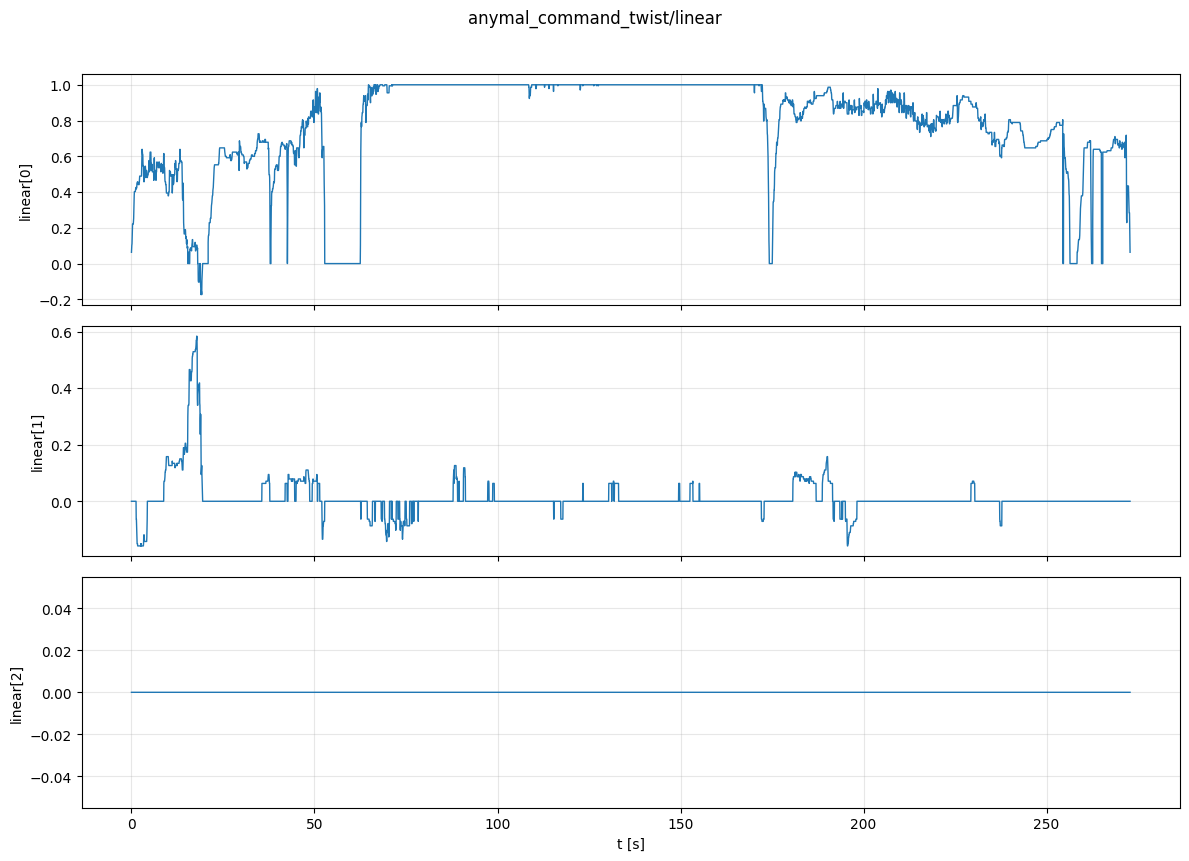

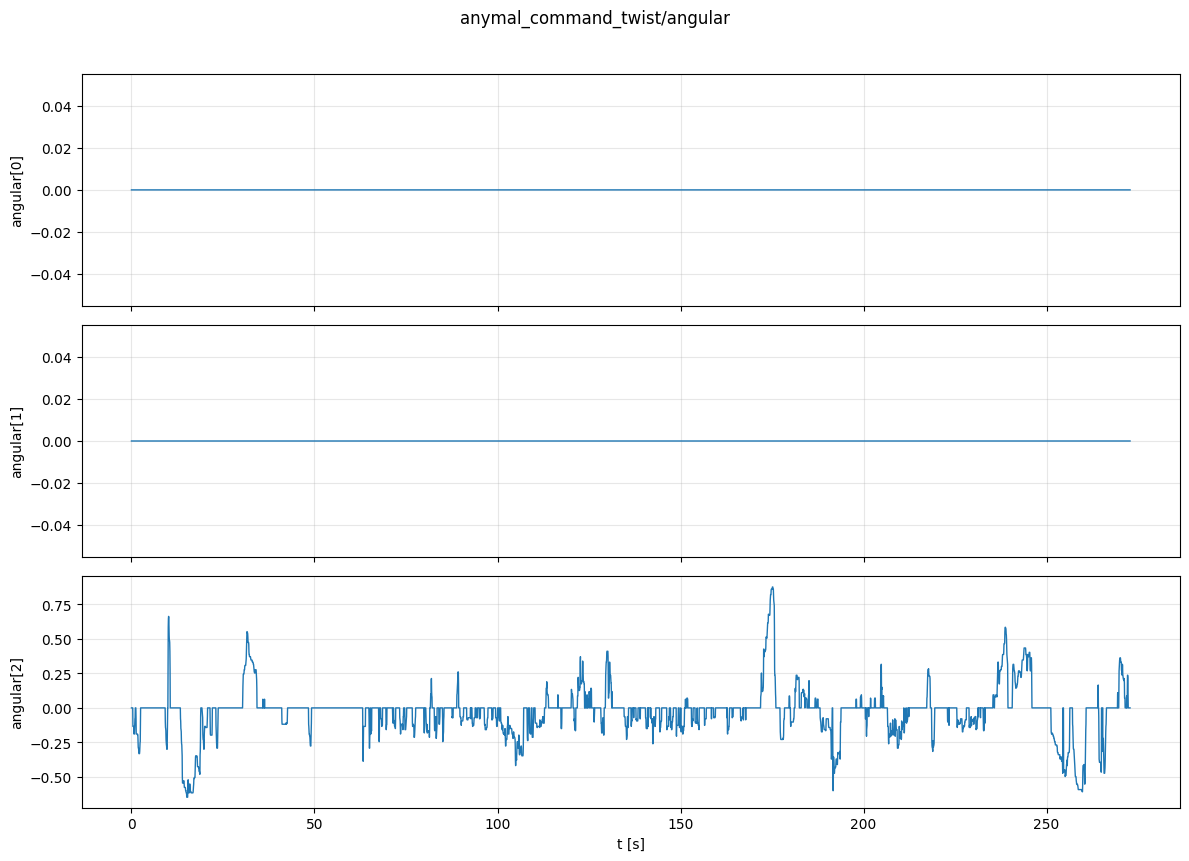

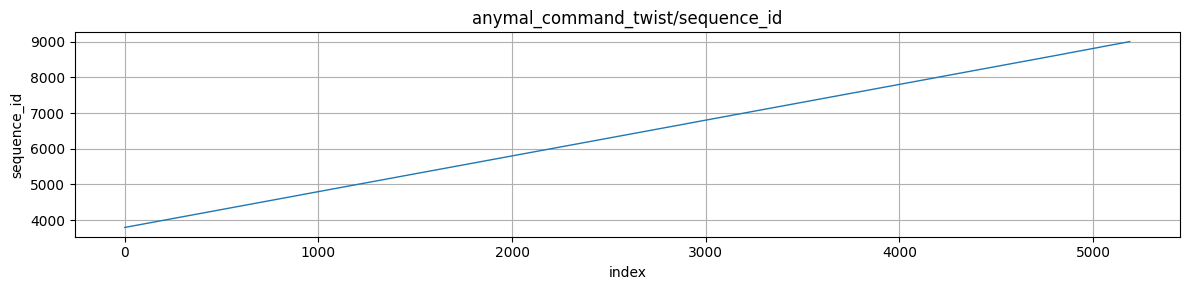


[cpt7_ie_tc_odometry] numeric keys: ['twist_ang', 'twist_lin', 'pose_orien', 'pose_pos', 'twist_cov', 'sequence_id', 'timestamp', 'pose_cov']


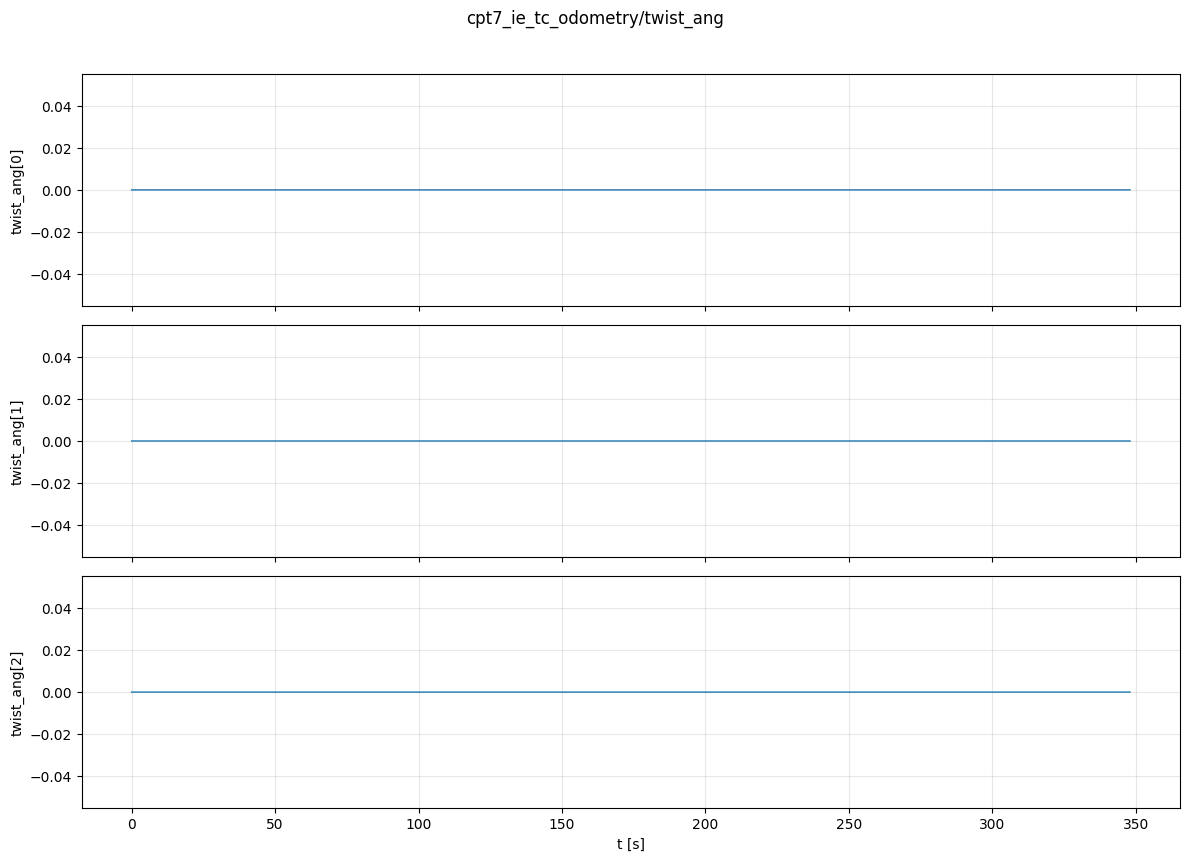

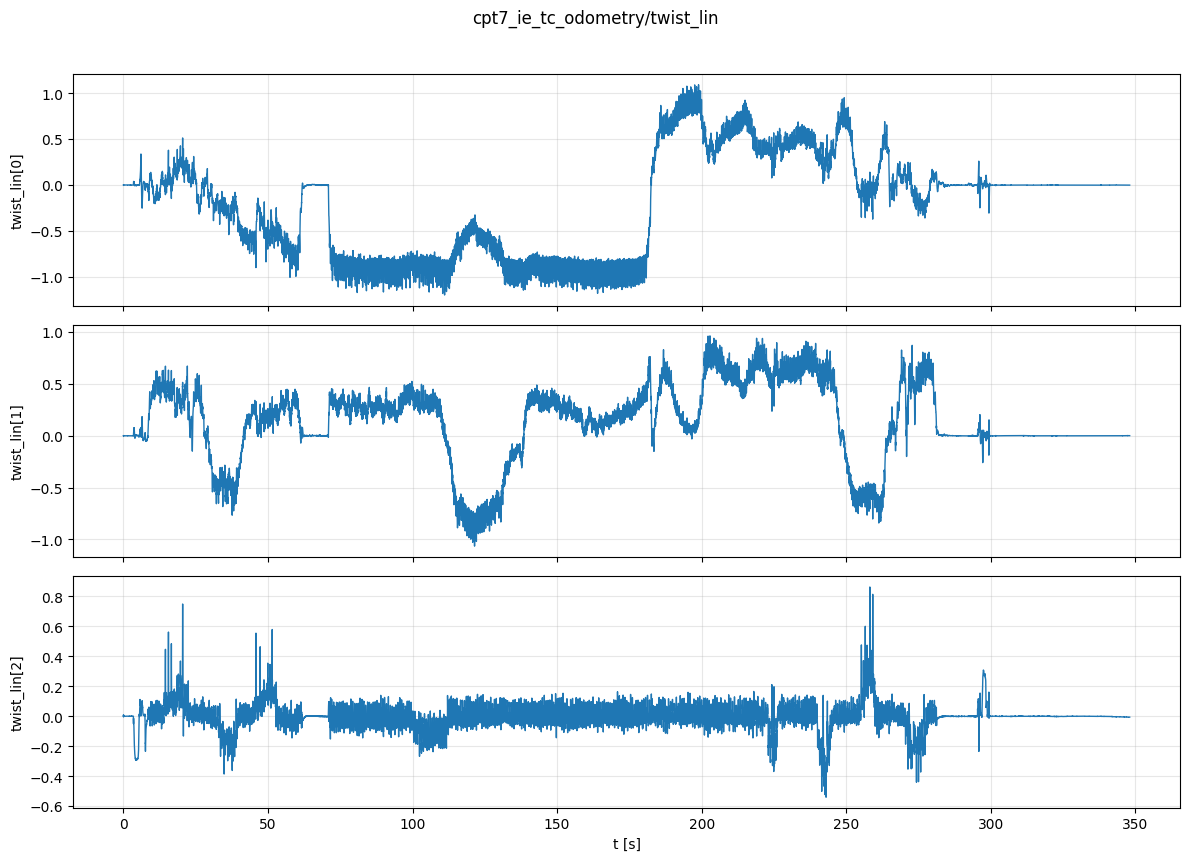

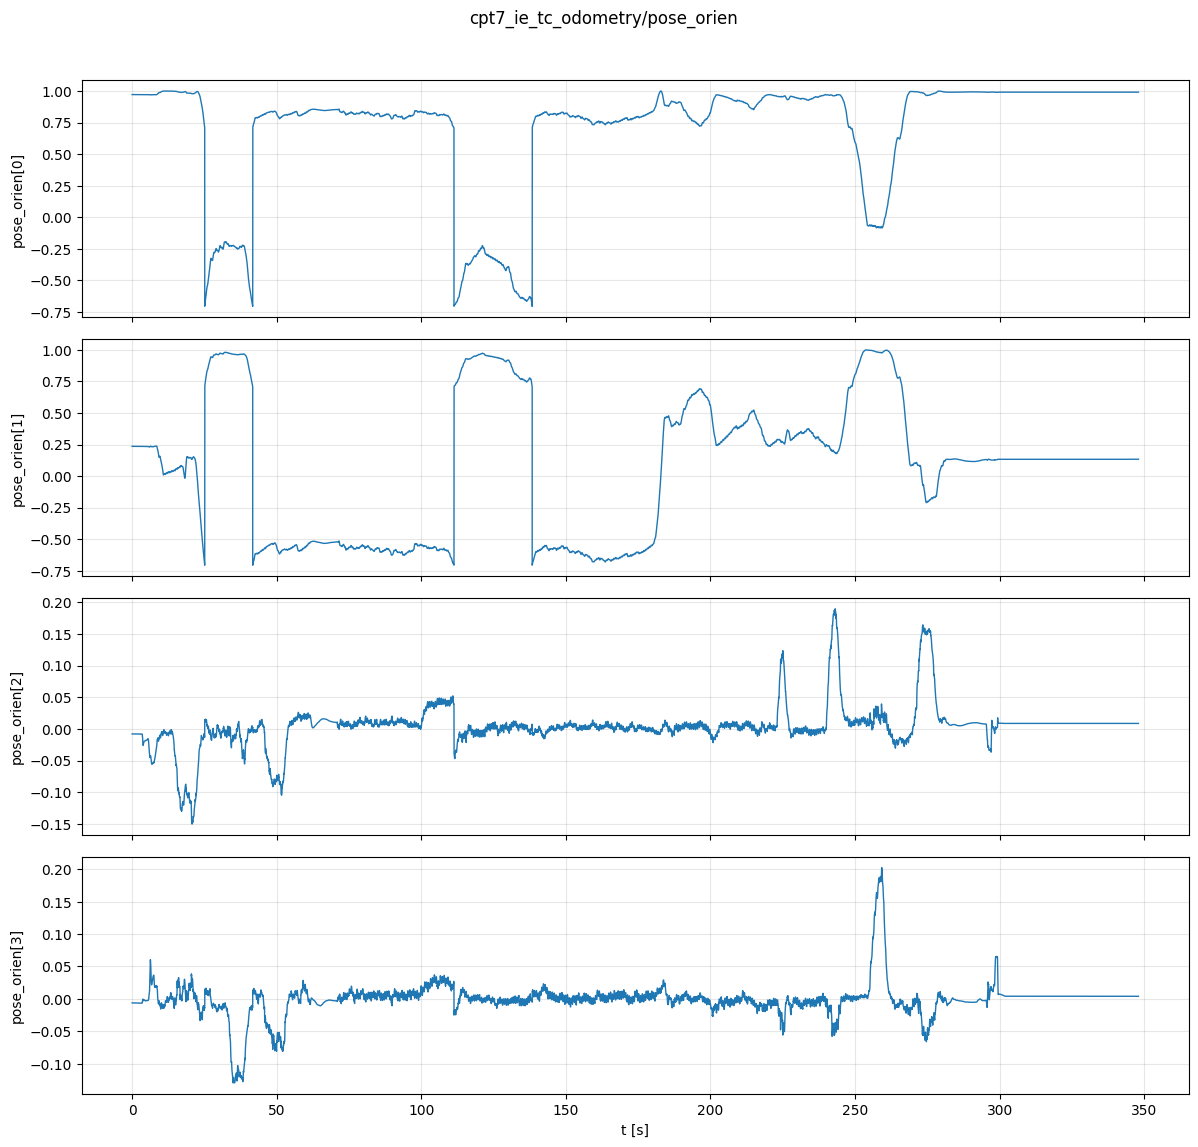

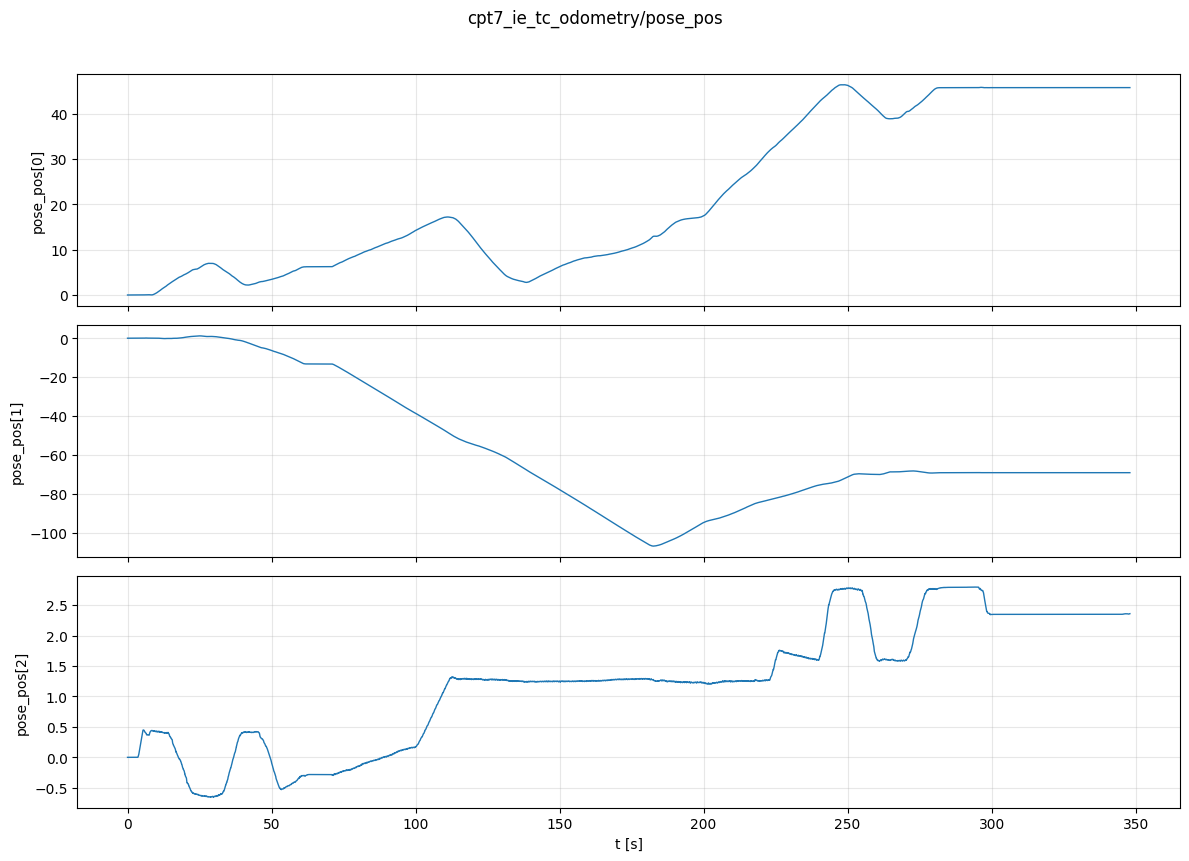

cpt7_ie_tc_odometry/twist_cov: ndim=3, shape=(69601, 6, 6), min=-1.309e-06, max=1.273e-05, mean=2.329e-07


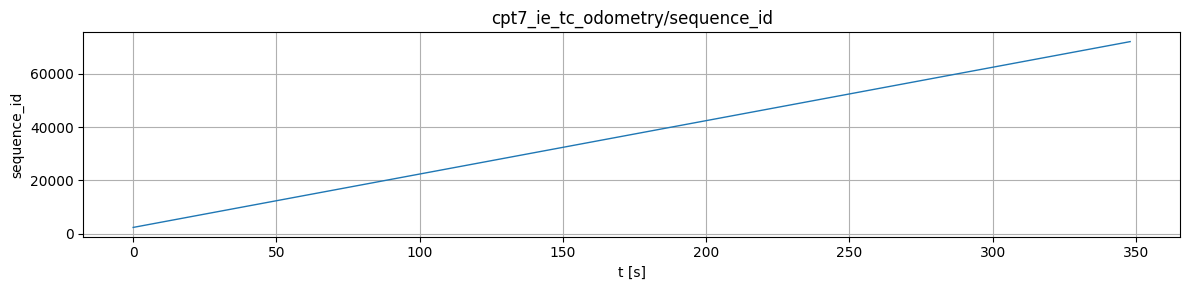

cpt7_ie_tc_odometry/pose_cov: ndim=3, shape=(69601, 6, 6), min=0, max=0, mean=0


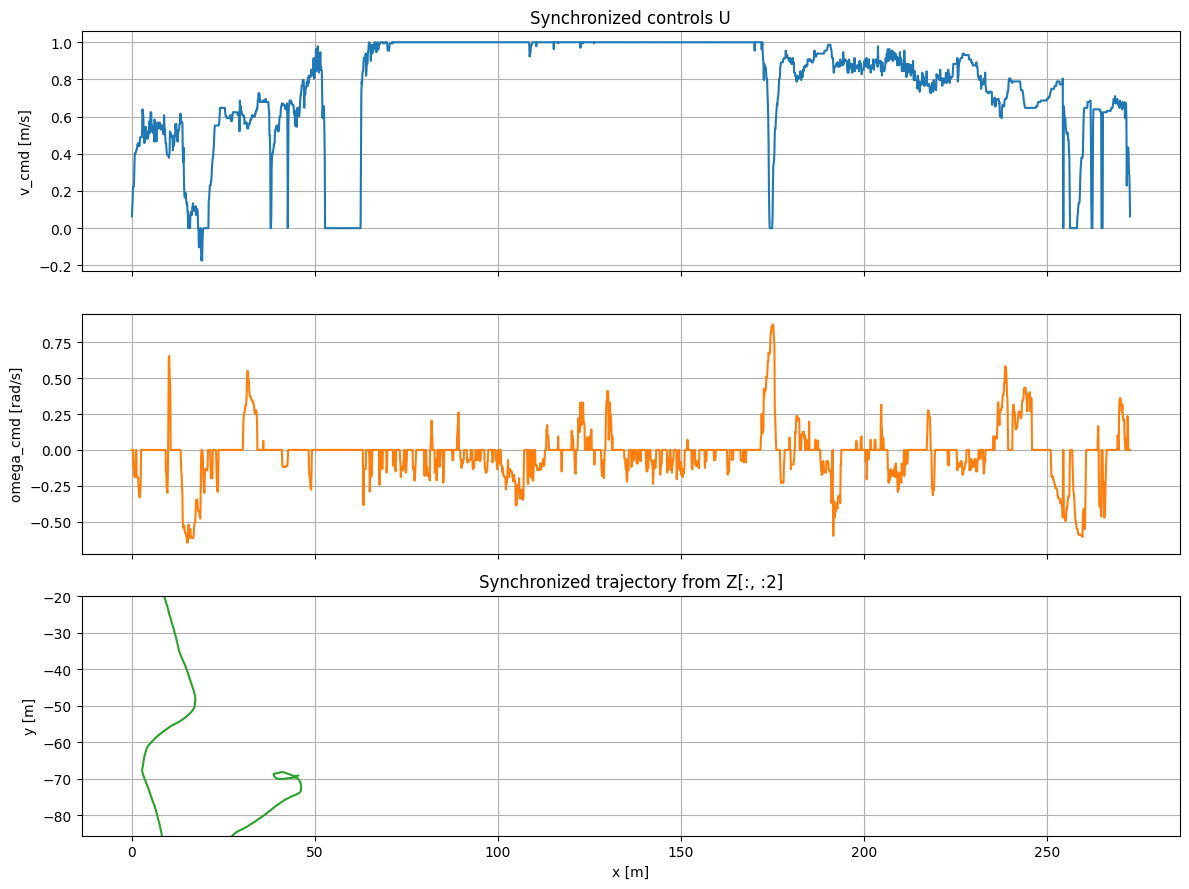

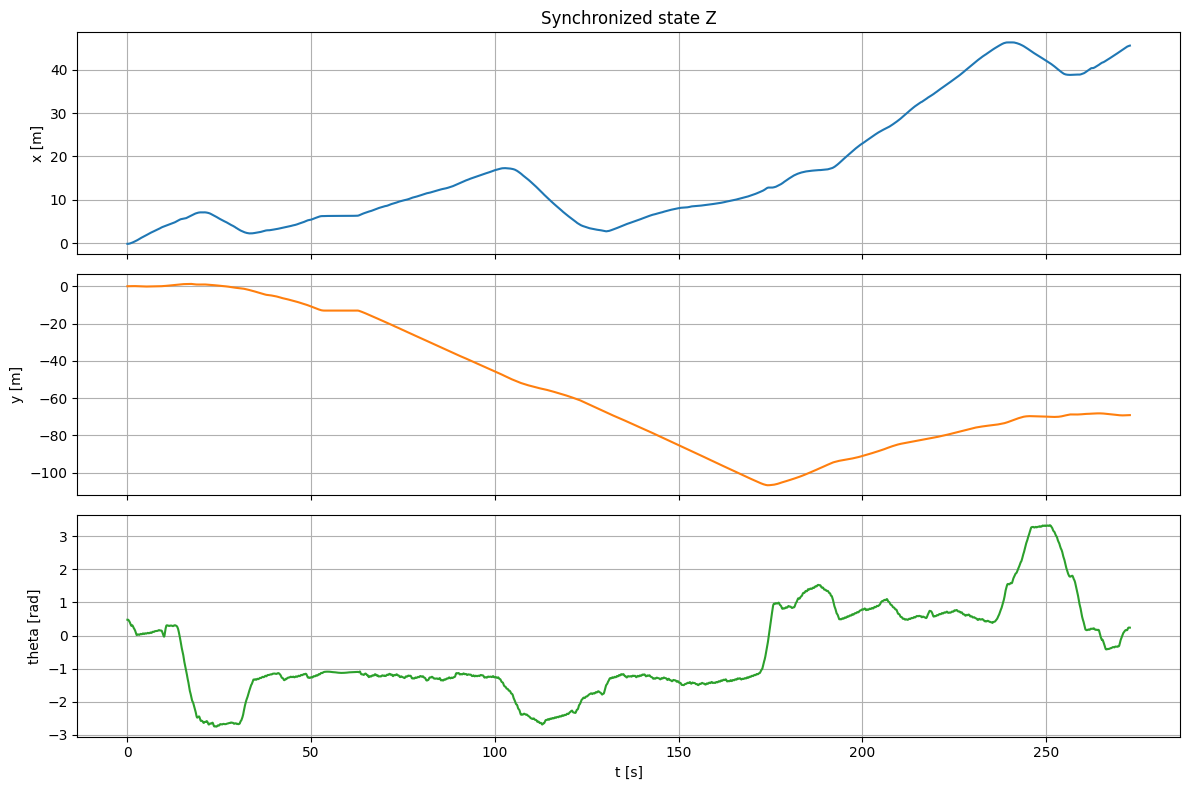

In [4]:
# 1) Visualize all numeric arrays from every topic used by the loader
_plot_numeric_topic("anymal_command_twist", cmd_data)
_plot_numeric_topic("cpt7_ie_tc_odometry", odom_data)

# 2) Visualize synchronized outputs from load_data_shared_timestamps()
t = _relative_time(shared_ts)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(t, U[:, 0], color="tab:blue")
axes[0].set_ylabel("v_cmd [m/s]")
axes[0].set_title("Synchronized controls U")

axes[1].plot(t, U[:, 1], color="tab:orange")
axes[1].set_ylabel("omega_cmd [rad/s]")

axes[2].plot(Z[:, 0], Z[:, 1], color="tab:green")
axes[2].set_ylabel("y [m]")
axes[2].set_xlabel("x [m]")
axes[2].set_title("Synchronized trajectory from Z[:, :2]")
axes[2].axis("equal")

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(t, Z[:, 0], label="x")
axes[0].set_ylabel("x [m]")
axes[0].set_title("Synchronized state Z")

axes[1].plot(t, Z[:, 1], label="y", color="tab:orange")
axes[1].set_ylabel("y [m]")

axes[2].plot(t, np.unwrap(Z[:, 2]), label="theta", color="tab:green")
axes[2].set_ylabel("theta [rad]")
axes[2].set_xlabel("t [s]")

fig.tight_layout()
plt.show()